# Лабораторная работа №4. Сравнительный анализ алгоритмов классификации
# Часть 1. Работа с наборами данных и постановка задачи

## Цель работы

Практическое освоение методов машинного обучения для решения задач классификации, изучение метрик оценки качества классификаторов, исследование влияния гиперпараметров на точность моделей, а также применение интерактивной визуализации.


## 1. Датасеты

**Подбор датасетов:** Самостоятельно выберите два различных набора данных для задачи бинарной или многоклассовой классификации (например, классические датасеты: отток клиентов, классификация вин, диагностика заболеваний или оценка кредитования из репозиториев Kaggle / UCI).

**Smoking** содержит медицинские и антропометрические показатели, а целевая колонка `smoking` кодирует класс 0 или 1. Колонка `ID` является идентификатором записи, а не содержательным измерением; её исключим из признаков, чтобы модель не пыталась использовать технический номер строки.

**Drug200** содержит 200 наблюдений и шесть столбцов. Целевая переменная `Drug` — название назначаемого препарата. Признаки `Sex`, `BP` и `Cholesterol` категориальные; `Age` и `Na_to_K` числовые.

In [46]:
import pandas as pd
smoking_df = pd.read_csv("./datasets/smoking.csv")
drug_df = pd.read_csv("./datasets/drug200.csv")

print("Smoking:", smoking_df.shape)
print("Drug200:", drug_df.shape)

Smoking: (55692, 27)
Drug200: (200, 6)


## 2. Постановка задач

### 2.1. Датасет Smoking — бинарная классификация

**Бизнес-задача.** Оценить, относится ли наблюдение к классу курящих.

**Объект классификации:** одна запись об обследованном человеке.

**Признаки:** пол, возраст, рост, масса тела, окружность талии, показатели зрения и слуха, давление, лабораторные показатели крови и другие медицинские признаки. Технический `ID` исключается.

**Целевая переменная:** `smoking`, где `0` — класс некурящих в разметке датасета, `1` — класс курящих.

### 2.2. Датасет Drug200 — многоклассовая классификация

**Бизнес-задача.** Предсказать одну из категорий препарата, представленных в учебном наборе данных.

**Объект классификации:** одна запись о пациенте.

**Признаки:** `Age` (возраст), `Sex` (пол), `BP` (категория давления), `Cholesterol` (категория холестерина), `Na_to_K` (отношение натрия к калию).

**Целевая переменная:** `Drug` — категория препарата, например `DrugY`, `drugA`, `drugB`, `drugC` или `drugX` (фактические классы будут выведены из данных).


## 3. Первичный осмотр данных


In [47]:
display(smoking_df.head())
display(drug_df.head())

,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar,smoking
0,0,F,40,155,60,81.3,1.2,1.0,1.0,1.0,114.0,73.0,94.0,215.0,82.0,73.0,126.0,12.9,1.0,0.7,18.0,19.0,27.0,Y,0,Y,0
1,1,F,40,160,60,81.0,0.8,0.6,1.0,1.0,119.0,70.0,130.0,192.0,115.0,42.0,127.0,12.7,1.0,0.6,22.0,19.0,18.0,Y,0,Y,0
2,2,M,55,170,60,80.0,0.8,0.8,1.0,1.0,138.0,86.0,89.0,242.0,182.0,55.0,151.0,15.8,1.0,1.0,21.0,16.0,22.0,Y,0,N,1
3,3,M,40,165,70,88.0,1.5,1.5,1.0,1.0,100.0,60.0,96.0,322.0,254.0,45.0,226.0,14.7,1.0,1.0,19.0,26.0,18.0,Y,0,Y,0
4,4,F,40,155,60,86.0,1.0,1.0,1.0,1.0,120.0,74.0,80.0,184.0,74.0,62.0,107.0,12.5,1.0,0.6,16.0,14.0,22.0,Y,0,N,0


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


In [48]:
print("=== Smoking: структура ===")
smoking_df.info()
print("\n=== Drug200: структура ===")
drug_df.info()

print("\n=== Smoking: описательная статистика ===")
display(smoking_df.describe(include="all").T)

print("\n=== Drug200: описательная статистика ===")
display(drug_df.describe(include="all").T)

=== Smoking: структура ===
<class 'pandas.DataFrame'>
RangeIndex: 55692 entries, 0 to 55691
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   55692 non-null  int64  
 1   gender               55692 non-null  str    
 2   age                  55692 non-null  int64  
 3   height(cm)           55692 non-null  int64  
 4   weight(kg)           55692 non-null  int64  
 5   waist(cm)            55692 non-null  float64
 6   eyesight(left)       55692 non-null  float64
 7   eyesight(right)      55692 non-null  float64
 8   hearing(left)        55692 non-null  float64
 9   hearing(right)       55692 non-null  float64
 10  systolic             55692 non-null  float64
 11  relaxation           55692 non-null  float64
 12  fasting blood sugar  55692 non-null  float64
 13  Cholesterol          55692 non-null  float64
 14  triglyceride         55692 non-null  float64
 15  HDL                 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,55692.0,NaN,NaN,NaN,27845.5,16077.039933,0.0,13922.75,27845.5,41768.25,55691.0
gender,55692,2,M,35401,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,55692.0,NaN,NaN,NaN,44.182917,12.071418,20.0,40.0,40.0,55.0,85.0
height(cm),55692.0,NaN,NaN,NaN,164.649321,9.194597,130.0,160.0,165.0,170.0,190.0
weight(kg),55692.0,NaN,NaN,NaN,65.864936,12.820306,30.0,55.0,65.0,75.0,135.0
waist(cm),55692.0,NaN,NaN,NaN,82.046418,9.274223,51.0,76.0,82.0,88.0,129.0
eyesight(left),55692.0,NaN,NaN,NaN,1.012623,0.486873,0.1,0.8,1.0,1.2,9.9
eyesight(right),55692.0,NaN,NaN,NaN,1.007443,0.485964,0.1,0.8,1.0,1.2,9.9
hearing(left),55692.0,NaN,NaN,NaN,1.025587,0.157902,1.0,1.0,1.0,1.0,2.0
hearing(right),55692.0,NaN,NaN,NaN,1.026144,0.159564,1.0,1.0,1.0,1.0,2.0



=== Drug200: описательная статистика ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,200.0,NaN,NaN,NaN,44.315,16.544315,15.0,31.0,45.0,58.0,74.0
Sex,200,2,M,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BP,200,3,HIGH,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cholesterol,200,2,HIGH,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Na_to_K,200.0,NaN,NaN,NaN,16.084485,7.223956,6.269,10.4455,13.9365,19.38,38.247
Drug,200,5,DrugY,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Пропуски, дубликаты и распределение целевых классов

In [49]:
def data_quality_report(df, target, name):
    print(f"=== {name} ===")
    report = pd.DataFrame({
        "Тип данных": df.dtypes.astype(str),
        "Пропуски": df.isna().sum(),
        "Доля пропусков, %": (df.isna().mean() * 100).round(2),
        "Уникальных значений": df.nunique(dropna=False),
    })
    display(report)
    print("Полных дубликатов:", int(df.duplicated().sum()))
    print("\nРаспределение целевого класса:")
    display(df[target].value_counts(dropna=False).rename("Количество").to_frame())
    display((df[target].value_counts(normalize=True, dropna=False) * 100)
            .round(2).rename("Доля, %").to_frame())

data_quality_report(smoking_df, "smoking", "Smoking")
data_quality_report(drug_df, "Drug", "Drug200")

=== Smoking ===


,Тип данных,Пропуски,"Доля пропусков, %",Уникальных значений
ID,int64,0,0.0,55692
gender,str,0,0.0,2
age,int64,0,0.0,14
height(cm),int64,0,0.0,13
weight(kg),int64,0,0.0,22
waist(cm),float64,0,0.0,566
eyesight(left),float64,0,0.0,19
eyesight(right),float64,0,0.0,17
hearing(left),float64,0,0.0,2
hearing(right),float64,0,0.0,2


Полных дубликатов: 0

Распределение целевого класса:


,Количество
smoking,
0,35237
1,20455


,"Доля, %"
smoking,
0,63.27
1,36.73


=== Drug200 ===


,Тип данных,Пропуски,"Доля пропусков, %",Уникальных значений
Age,int64,0,0.0,57
Sex,str,0,0.0,2
BP,str,0,0.0,3
Cholesterol,str,0,0.0,2
Na_to_K,float64,0,0.0,198
Drug,str,0,0.0,5


Полных дубликатов: 0

Распределение целевого класса:


,Количество
Drug,
DrugY,91
drugX,54
drugA,23
drugC,16
drugB,16


,"Доля, %"
Drug,
DrugY,45.5
drugX,27.0
drugA,11.5
drugC,8.0
drugB,8.0


### Распределение

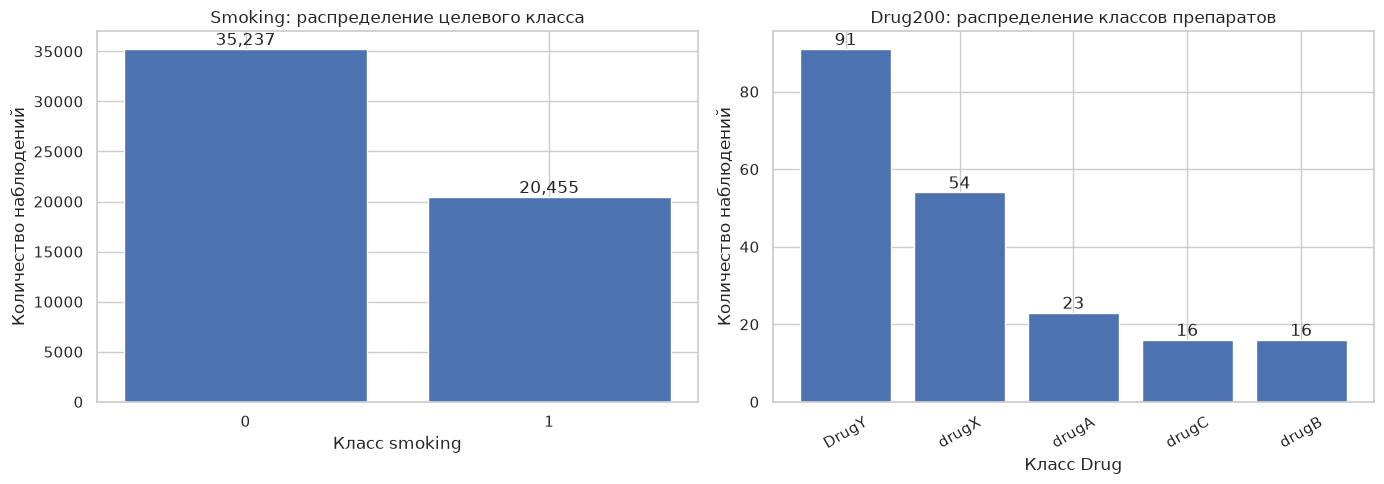

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

smoking_counts = smoking_df["smoking"].value_counts().sort_index()
axes[0].bar(smoking_counts.index.astype(str), smoking_counts.values)
axes[0].set_title("Smoking: распределение целевого класса")
axes[0].set_xlabel("Класс smoking")
axes[0].set_ylabel("Количество наблюдений")
for i, v in enumerate(smoking_counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

drug_counts = drug_df["Drug"].value_counts()
axes[1].bar(drug_counts.index.astype(str), drug_counts.values)
axes[1].set_title("Drug200: распределение классов препаратов")
axes[1].set_xlabel("Класс Drug")
axes[1].set_ylabel("Количество наблюдений")
axes[1].tick_params(axis="x", rotation=30)
for i, v in enumerate(drug_counts.values):
    axes[1].text(i, v, str(v), ha="center", va="bottom")

plt.tight_layout()
plt.show()

## 5. Исследовательский анализ признаков

Для Smoking построим распределения нескольких числовых показателей и сравним их по классам `smoking`. Для Drug200 посмотрим на распределение `Na_to_K` по категориям препарата и частоты категориальных признаков.

Эти графики нужны не для того, чтобы заранее «подогнать» модель под тестовые данные, а чтобы понять состав набора и сформировать гипотезы о возможных зависимостях. Визуальное различие распределений само по себе не доказывает причинно-следственную связь.

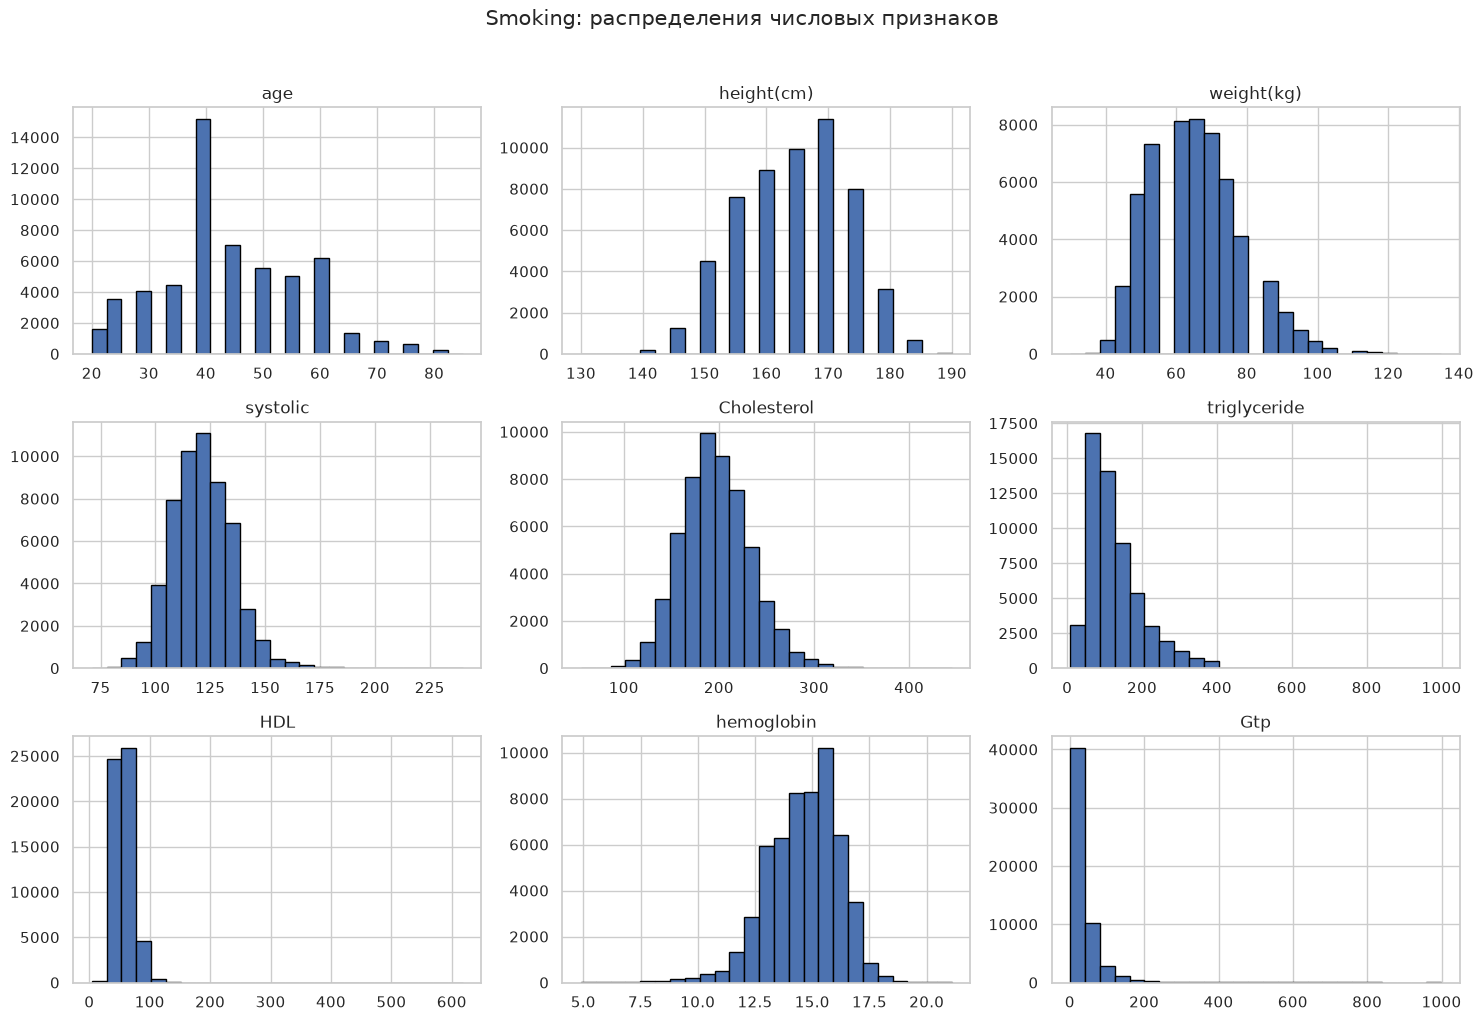

In [51]:
smoking_numeric = [
    c for c in ["age", "height(cm)", "weight(kg)", "systolic",
                "Cholesterol", "triglyceride", "HDL", "hemoglobin", "Gtp"]
    if c in smoking_df.columns
]
smoking_df[smoking_numeric].hist(figsize=(15, 10), bins=25, edgecolor="black")
plt.suptitle("Smoking: распределения числовых признаков", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

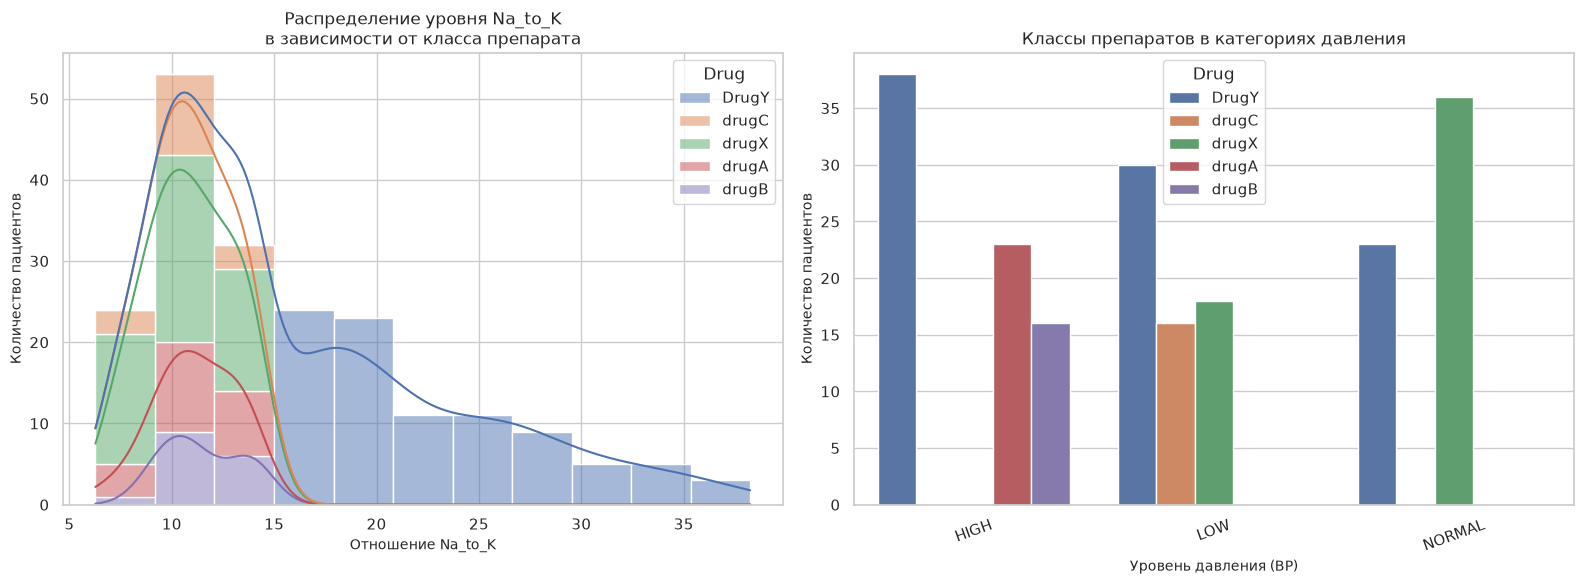

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(
    data=drug_df, x="Na_to_K", hue="Drug", multiple="stack", kde=True, ax=axes[0]
)
axes[0].set_title(
    "Распределение уровня Na_to_K\nв зависимости от класса препарата",
    fontsize=12,
)
axes[0].set_xlabel("Отношение Na_to_K", fontsize=10)
axes[0].set_ylabel("Количество пациентов", fontsize=10)

sns.countplot(data=drug_df, x="BP", hue="Drug", ax=axes[1])
axes[1].set_title("Классы препаратов в категориях давления", fontsize=12)
axes[1].set_xlabel("Уровень давления (BP)", fontsize=10)
axes[1].set_ylabel("Количество пациентов", fontsize=10)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


## 6. Подготовка признаков и целевых переменных

Для каждого датасета выделяем `X` — матрицу признаков, и `y` — целевой вектор. Из Smoking удаляем `ID`, потому что это технический идентификатор. Из Drug200 целевой столбец `Drug` не должен попадать в `X`.

В Smoking оставляем все остальные содержательные признаки. Для числовых столбцов используем медиану для заполнения пропусков и `StandardScaler`. Для категориальных — заполнение наиболее частой категорией и `OneHotEncoder`. One-hot-кодирование преобразует категории вроде `BP=HIGH` в числовые индикаторные признаки.

Для Drug200 применяется тот же подход: `Sex`, `BP`, `Cholesterol` кодируются, а `Age` и `Na_to_K` масштабируются.

In [53]:
X_smoking = smoking_df.drop(columns=["smoking", "ID"], errors="ignore")
y_smoking = smoking_df["smoking"].astype(int)

X_drug = drug_df.drop(columns=["Drug"])
y_drug = drug_df["Drug"].astype(str)

print("Smoking: X =", X_smoking.shape, ", y =", y_smoking.shape)
print("Drug200: X =", X_drug.shape, ", y =", y_drug.shape)
print("\nТипы признаков Smoking:")
display(X_smoking.dtypes.value_counts().rename("Количество столбцов").to_frame())
print("\nТипы признаков Drug200:")
display(X_drug.dtypes.to_frame("Тип данных"))

Smoking: X = (55692, 25) , y = (55692,)
Drug200: X = (200, 5) , y = (200,)

Типы признаков Smoking:


,Количество столбцов
float64,18
int64,4
str,3



Типы признаков Drug200:


,Тип данных
Age,int64
Sex,str
BP,str
Cholesterol,str
Na_to_K,float64


## 7. Разделение на train и test

Делим данные в пропорции 80/20. Обучающая выборка используется для обучения и подбора гиперпараметров, тестовая — только для итоговой оценки после выбора модели.

Аргумент `stratify=y` поддерживает в train и test близкие к исходным доли каждого класса. Это особенно важно для многоклассового Drug200, где некоторые классы могут быть представлены малым числом объектов.

Для Smoking используется полный набор данных в части 1. Чтобы ускорить перебор гиперпараметров в части 2, в ноутбуке моделирования будет предусмотрен воспроизводимый стратифицированный поднабор; это будет явно отражено в анализе.

In [56]:
X_train_smoking, X_test_smoking, y_train_smoking, y_test_smoking = train_test_split(
    X_smoking, y_smoking, test_size=0.2, random_state=42, stratify=y_smoking
)
X_train_drug, X_test_drug, y_train_drug, y_test_drug = train_test_split(
    X_drug, y_drug, test_size=0.2, random_state=42, stratify=y_drug
)

def compare_class_shares(y, y_train, y_test, name):
    comparison = pd.DataFrame({
        "Исходные данные, %": y.value_counts(normalize=True) * 100,
        "Train, %": y_train.value_counts(normalize=True) * 100,
        "Test, %": y_test.value_counts(normalize=True) * 100,
    }).fillna(0).round(2)
    print(name)
    display(comparison)

compare_class_shares(y_smoking, y_train_smoking, y_test_smoking, "Smoking")
compare_class_shares(y_drug, y_train_drug, y_test_drug, "Drug200")
print("Smoking: train", X_train_smoking.shape, "test", X_test_smoking.shape)
print("Drug200: train", X_train_drug.shape, "test", X_test_drug.shape)

Smoking


,"Исходные данные, %","Train, %","Test, %"
smoking,,,
0,63.27,63.27,63.27
1,36.73,36.73,36.73


Drug200


,"Исходные данные, %","Train, %","Test, %"
Drug,,,
DrugY,45.5,45.62,45.0
drugA,11.5,11.25,12.5
drugB,8.0,8.12,7.5
drugC,8.0,8.12,7.5
drugX,27.0,26.88,27.5


Smoking: train (44553, 25) test (11139, 25)
Drug200: train (160, 5) test (40, 5)
